# TP1 : Résolution approchée de $f(x)=0$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Dans ce TP, on souhaite étudier la vitesse de convergence des différentes méthodes du cours pour résoudre l'équation :
$$ \mathrm{e}^{-x} = x$$
Cette équation a été étudiée en TD (exercice 2), on sait qu'elle admet une unique solution $x_*$ et que $x_* \in [0, 1]$.

## Dichotomie

1. Écrire une fonction qui renvoie la liste de tous les itérés $x_n$ (et pas seulement la valeur finale : cela servira plus loin à tracer la convergence) par la méthode de la dichotomie appliquée à une fonction $f$ sur un intervalle $[a,b]$.
2. L'appliquer à la fonction $f(x) = \mathrm{e}^{-x}-x$ sur $[0,1]$ pour obtenir une approximation de $x_*$ à $10^{-8}$ près. Afficher le nombre d'itérations effectuées.

In [2]:
def dichotomie(f, a, b, eps):
    """
    Recherche d'un zero de f sur [a,b] par dichotomie.
    Hypothese : f(a)*f(b) < 0.
    Renvoie la liste des iteres x_0, x_1, ..., x_n (le milieu a chaque etape).
    Le critere d'arret est (b_n - a_n)/2 < eps.
    """
    fa = f(a)
    fb = f(b)
    if fa * fb > 0:
        raise TypeError("f(a) et f(b) ne sont pas de signes opposés.")
    m = (a + b) / 2
    res = [m]
    while (b - a) / 2 > eps:
        fm = f(m)
        if fa * fm < 0:
            b = m
        else:
            a = m
            fa = fm
        m = (a + b) / 2
        res.append(m)
    return np.array(res)

In [3]:
def f(x): return np.exp(-x) - x

x_dicho = dichotomie(f, a=0, b=1, eps=1e-8)
print(f"Nombre d'itération de la dichotomie : {x_dicho.size - 1}.")
print(f"Valeur approchée de la racine : {x_dicho[-1]}.")

Nombre d'itération de la dichotomie : 26.
Valeur approchée de la racine : 0.5671432837843895.


## Méthode de Picard

1. Écrire une fonction qui calcule la suite des itérés $x_{n+1} = F(x_n)$ d'une fonction $F$.
2. Pourquoi fixe-t-on un nombre maximal d'itération ?
3. Appliquer à la fonction $F(x) = \mathrm{e}^{-x}$ et $x_0 \in [0,1]$ pour obtenir une approximation de $x_*$ à $10^{-8}$ près et afficher le nombre d'itérations effectuées. Essayer pour plusieurs initialisations $x_0$.

In [4]:
def picard(F, x0, eps, nmax=100):
    """
    Recherche d'un point fixe de F par itérations x_{n+1} = F(x_n).
    Renvoie la liste des itérées x_0, x_1, ..., x_n.
    Le critere d'arret est |x_{n+1} - x_n| < eps ou n > nmax.
    """
    res = [x0] # contiendra les résultats
    for n in range(1, nmax):
        x1 = F(x0)
        if abs(x1 - x0) < eps:   # si la condition d'arrêt est vérifiée
            return np.array(res) # on s'arrête et on renvoie la liste
        else:
            res.append(x1)       # sinon, on rajoute x1 à la liste
            x0 = x1              # et on met à jour x0

    # si la boucle for est finie, on a dépassé le nb max d'itérations
    print("Nombre maximum d'itérations atteint.")
    return np.array(res)

# Remarque : on fixe un nombre maximal d'itérations car la suite des itérées
# peut être divergente (si |F'(racine)|>1 par ex.), ou converger trop lentement.

In [5]:
def F(x): return np.exp(-x)

x_picard = picard(F, x0=0.5, eps=1e-8)
print(f"Nombre d'itération de la méthode de Picard : {x_picard.size - 1}.")
print(f"Valeur approchée de la racine : {x_picard[-1]}.")

Nombre d'itération de la méthode de Picard : 29.
Valeur approchée de la racine : 0.5671432953443666.


## Méthode de Newton

1. Écrire une fonction qui renvoie la liste des itérés $x_n$ de la méthode de Newton appliquée à une fonction $f$.
2. Appliquer à la fonction $f(x) = \mathrm{e}^{-x}-x$ et $x_0 \in [0,1]$ pour obtenir une approximation de $x_*$ à $10^{-8}$ près. Afficher le nombre d'itérations effectuées.

In [6]:
def newton(f, fprime, x0, eps, nmax=100):
    """
    Methode de Newton pour resoudre f(x)=0.
    Renvoie la liste des iteres x_0, x_1, ..., x_n.
    Critere d'arret : |x_{n+1} - x_n| < eps ou n > nmax.
    """
    def F(x): return x - f(x) / fprime(x) # on définit la fonction d'itération
    # de la méthode de Newton, puis on utilise Picard pour l'itérer. 
    
    return picard(F, x0, eps, nmax)

In [7]:
def f_prime(x): return -np.exp(-x) - 1
x_newton = newton(f, f_prime, x0=0, eps=1e-8)
print(f"Nombre d'itération de la méthode de Newton : {x_newton.size - 1}.")
print(f"Valeur approchée de la racine : {x_newton[-1]}.")

Nombre d'itération de la méthode de Newton : 4.
Valeur approchée de la racine : 0.5671432904097811.


## Méthode de la sécante

1. Écrire une fonction qui renvoie la liste des itérés $x_n$ de la méthode de la sécante appliquée à une fonction $f$.
2. Appliquer à la fonction $f(x) = \mathrm{e}^{-x}-x$ pour obtenir une approximation de $x_*$ à $10^{-8}$ près. Afficher le nombre d'itérations effectuées.

In [8]:
def secante(f, x0, x1, eps, nmax=100):
    """
    Methode de la secante pour resoudre f(x)=0.
    Renvoie la liste des iteres x_0, x_1, ..., x_n.
    Critere d'arret : |x_{n+1} - x_n| < eps ou n > nmax.
    """
    res = [x0, x1]
    f0 = f(x0)
    f1 = f(x1)
    for n in range(2, nmax):
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        if abs(x2 - x1) < eps:
            return np.array(res)
        else:
            res.append(x2)
            x0 = x1
            f0 = f1
            x1 = x2
            f1 = f(x2)
    
    print("Nombre maximum d'itérations atteint")
    return np.array(res)

In [9]:
x_secante = secante(f, x0=0, x1=1, eps=1e-8)
print(f"Nombre d'itération de la méthode de la sécante : {x_secante.size - 1}.")
print(f"Valeur approchée de la racine : {x_secante[-1]}.")

Nombre d'itération de la méthode de la sécante : 6.
Valeur approchée de la racine : 0.5671432904097046.


## Comparaison des vitesses de convergence

On cherche à visualiser les résultats du cours sur la vitesse de convergence des différentes méthodes.

1. Utiliser la méthode de Newton pour approcher $x_*$ à $10^{-15}$ près. On utilisera cette valeur comme référence pour $x_*$ dans la suite.
2. Pour chacune des méthodes, calculer la liste des erreurs $e_n = |x_n - x_*|$.
3. Tracer dans un repère semi-logarithmique les erreurs des méthodes.
4. Interpréter : quelles méthodes ont une convergence linéaire ? quelles méthodes ont une convergence superlinéaire ?
5. Pour la méthode de Newton et la méthode de la sécante, tracer dans un repère log-log les points de coordonnées $(e_n, e_{n+1})$. Qu'oberve-t-on ? Expliquer.
6. Déterminer numériquement l'ordre de la méthode de Newton et l'ordre de la méthode de la sécante.

In [10]:
racine = newton(f, f_prime, 0, eps=1e-15)[-1]

# dans les fonctions précédentes, on renvoie à chaque fois un vecteur numpy
# et pas juste une liste. Aisni, x_dicho est un vecteur donc on peut lui soustraire
# un nombre (si c'était juste une liste, Python ne comprendrait pas).
err_dicho = np.abs(x_dicho - racine)
err_picard = np.abs(x_picard - racine)
err_newton = np.abs(x_newton - racine)
err_secante = np.abs(x_secante - racine)

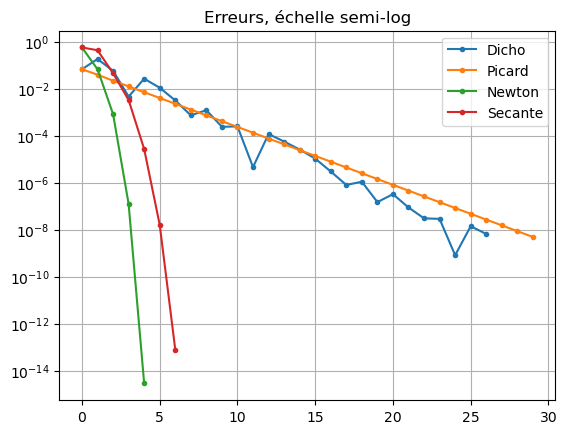

In [11]:
plt.figure()
plt.plot(err_dicho, ".-", label = "Dicho")
plt.plot(err_picard, ".-", label = "Picard")
plt.plot(err_newton, ".-", label = "Newton")
plt.plot(err_secante, ".-", label = "Secante")
plt.yscale("log")
plt.legend()
plt.title("Erreurs, échelle semi-log")
plt.grid()
plt.show()

Les méthodes de la dichotomie et de Picard sont linéaires (le log de l'erreur décroit linéairement), alors que Newton et la sécante sont superlinéaires (le log de l'erreur est concave).

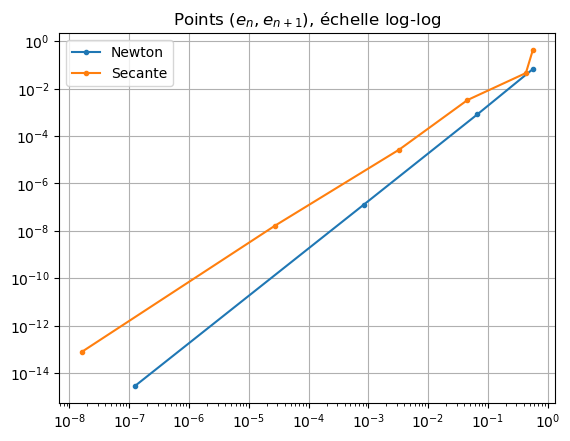

In [12]:
# err_newton[:-1] contient les erreurs sauf la dernière :
# [e_0, e_1, ..., e_{n-1}]
# et err_newton[1:] contient les erreurs sauf la première :
# [e_1, e_2, ..., e_n]
# Quant on écrit plt.plot(err_newton[:-1], err_newton[1:]), on trace donc bien
# les points de coordonnées (e_i, e_{i+1})

plt.figure()
plt.plot(err_newton[:-1], err_newton[1:], ".-", label = "Newton")
plt.plot(err_secante[:-1], err_secante[1:], ".-", label = "Secante")
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.title(r"Points $(e_n, e_{n+1})$, échelle log-log")
plt.grid()
plt.show()

Pour une convergence d'ordre $p$, l'erreur se comporte comme $e_{n+1} \approx C e_n^p$, donc $\log(e_{n+1}) \approx p \log(e_n) + \log(C)$. Dans un repère log-log, les points $(e_n, e_{n+1})$ sont alignés approximativement sur une droite de pente $p$.

In [13]:
# si x = (x_0,...,x_n) et y = (y_0,...,y_n) sont des vecteurs, la fonction
# np.polyfit(x, y, deg=1) calcule la "meilleure" droite passant par les points
# de coordonnées (x_i, y_i). Cette fonction renvoie une liste (a, b) contenant
# la pente a et l'ordonnée à l'origine b de la droite en question. En ce qui
# nous concerne, on ne veut que la pente.

p_newton = np.polyfit(np.log(err_newton[:-1]), np.log(err_newton[1:]), deg=1)[0]
p_secante = np.polyfit(np.log(err_secante[:-1]), np.log(err_secante[1:]), deg=1)[0]

print(f"Numériquement, l'ordre de la méthode de Newton est approx. p = {p_newton}.")
print(f"Numériquement, l'ordre de la méthode de la sécante est approx. p = {p_secante}")

Numériquement, l'ordre de la méthode de Newton est approx. p = 2.005764563553391.
Numériquement, l'ordre de la méthode de la sécante est approx. p = 1.6368974654856685


**Remarque.** On a vu en cours que la méthode de Newton était d'ordre 2 en général, ce qu'on retrouve ici. Pour la méthode de la sécante, on peut montrer qu'elle est en fait d'ordre ≈1,618 (le nombre d'or).

## Accélération de convergence

Étant donnée une suite $(u_n)_{n\in\mathbb N}$, on définit sa transformée d'Aitken (voir exercice 4 du TD) :
$$v_n = u_n - \frac{(\Delta u_n)^2}{\Delta^2 u_n}$$
avec $\Delta u_n = u_{n+1} - u_n$ et $\Delta^2 u_n = \Delta(\Delta u_n) = u_{n+2} - 2u_{n+1}+u_n$.

1. Écrire une fonction `aitken` qui prend une liste et renvoie sa transformée d'Aitken. On pourra utiliser la fonction `np.diff` pour vectoriser les calculs.
2. L'appliquer pour accélérer la convergence de la méthode de Picard.
3. Tracer et comparer les vitesses de convergence.

In [14]:
def aitken(u):
    u = np.asarray(u) # on convertit u en vecteur, si ce n'était pas le cas.
    Du = np.diff(u)
    DDu = np.diff(u, n=2)
    return u[:-2] - Du[:-1]**2 / DDu
# attention au fait que si u est de taille n, alors Du est de taille n-1 et
# DDu est de taille n-2. Pour pouvoir effectuer les opérations entre vecteurs,
# il faut qu'ils aient la même taille, c'est pourquoi on laisse tomber
# les 2 dernières valeurs de u et la dernière valeure de Du dans le calcul.

In [15]:
x_aitken = aitken(x_picard)
err_aitken = np.abs(x_aitken - racine)
err_aitken = err_aitken

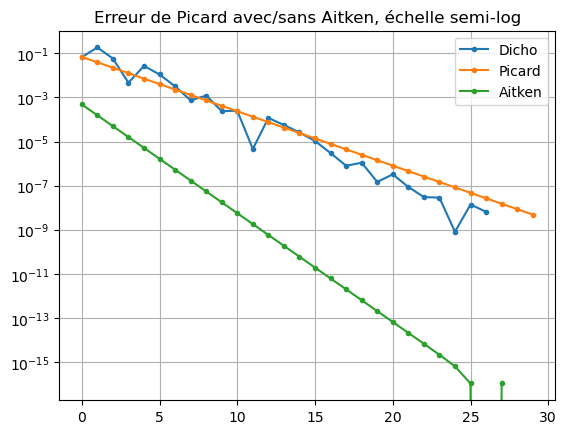

In [16]:
plt.figure()
plt.plot(err_dicho, ".-", label = "Dicho")
plt.plot(err_picard, ".-", label = "Picard")
plt.plot(err_aitken, ".-", label = "Aitken")
plt.yscale("log")
plt.legend()
plt.title("Erreur de Picard avec/sans Aitken, échelle semi-log")
plt.grid()
plt.show()

Pour une vitesse de convergence linéaire, on sait que l'erreur se comporte comme $e_n \approx C q^n$, donc $\log(e_n) \approx \log(C) + n\log(q)$. Dans un repère semi-logarithmique, les points $(n, e_n)$ sont approximativement alignés sur une droite donc la pente est $\log(q)$.

In [17]:
q_dicho = np.exp(np.polyfit(np.arange(err_dicho.size), np.log(err_dicho), deg=1)[0])
q_picard = np.exp(np.polyfit(np.arange(err_picard.size), np.log(err_picard), deg=1)[0])
q_aitken = np.exp(np.polyfit(np.arange(20), np.log(err_aitken[:20]), deg=1)[0])
# pour Aitken, l'erreur finit par atteindre 10^-16 et ne pas aller plus bas. Donc
# pour calculer la pente de la droite, on ne regarde que les 20 premiers termes
# par exemple.
print(f"Vitesse de la dichotomie : q = {q_dicho}.")
print(f"Vitesse de Picard sans accélération : q = {q_picard}.")
print(f"Vitesse de Picard avec Aitken : q = {q_aitken}")

Vitesse de la dichotomie : q = 0.5022920590514817.
Vitesse de Picard sans accélération : q = 0.5671914560078578.
Vitesse de Picard avec Aitken : q = 0.32165902503457905


On retrouve que la dichotomie converge à la même vitesse qu'une suite géométrique de raison $\frac 12$. La méthode de Picard a une vitesse de convergence plus lente (mais mieux que le ≈0.7 qu'on avait trouvé à l'exercice 2 du TD). On voit que le procédé d'Aitken a bien accéléré la vitesse de convergence.